In [3]:
import numpy as np
import skimage.io
import skimage.color
import skimage.filters
import skimage.transform
from skimage import img_as_ubyte
import matplotlib.pyplot as plt
import constants
import IPython.display as d
import json
import os
import time
import torch
import torchvision
from torchvision import transforms, utils, datasets
from torch.utils.data import Dataset, DataLoader
from torch.autograd import Variable
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import shutil
import pandas as pd
from sklearn import metrics
from PIL import Image
import cv2

## Downsample

Scale down images to 64x64

In [ ]:
dir = "./data/data_512/images_1-16_128"
dir_downsampled = "./data/data_512/images_1-16_64"
scale = 0.5

aantal = len(os.listdir(dir))
teller_files = 0

for filename in os.listdir(dir):
    img = skimage.io.imread(f"{dir}/{filename}")
    img_downscaled = skimage.transform.rescale(img, scale, anti_aliasing=True, channel_axis=2)
    skimage.io.imsave(f"{dir_downsampled}/{filename}", img_as_ubyte(img_downscaled))
    teller_files += 1
    if(not teller_files%100):
        print(f"{teller_files}/{aantal}")   

## Splitting images in 4 pieces

Manually split images in four pieces after inference for the next model

In [ ]:
dir = "./data/data_512/images_1-16_128"
dir_splitted = "./data/data_512/images_1-64_64"
dir_labels = "./data/data_512/labels_1-16"
dir_labels_splitted = "./data/data_512/labels_1-64"

aantal = len(os.listdir(dir))
teller_files = 0

for filename in os.listdir(dir):
    name_short = filename.split(".")[0]
    im = skimage.io.imread(f"{dir}/{filename}")
    M = im.shape[0]//2
    N = im.shape[1]//2
    tiles = [im[x:x+M,y:y+N] for x in range(0,im.shape[0],M) for y in range(0,im.shape[1],N)]
    try:
        labels = open(f"{dir_labels}/{name_short}.txt")
        lines = [line.rstrip() for line in labels.readlines()]
    except:
        lines = []
    for i in range(1, len(tiles)+1):
        skimage.io.imsave(f"{dir_splitted}/{name_short}_{i}.JPG", tiles[i-1])
        labels_part = open(f"{dir_labels_splitted}/{name_short}_{i}.txt", "a")
        for line in lines:
            name, x_center, y_center, width, height = [float(s) for s in line.split("\t")]
            if i == 1 and x_center < 0.5 and y_center < 0.5:
                labels_part.write("0\t"+str(x_center*2)+"\t"+str(y_center*2)+"\t"+str(width*2)+"\t"+str(height*2)+"\n")
            elif i == 2 and x_center > 0.5 and y_center < 0.5:
                labels_part.write("0\t"+str((x_center-0.5)*2)+"\t"+str(y_center*2)+"\t"+str(width*2)+"\t"+str(height*2)+"\n")
            elif i == 3 and x_center < 0.5 and y_center > 0.5:
                labels_part.write("0\t"+str(x_center*2)+"\t"+str((y_center-0.5)*2)+"\t"+str(width*2)+"\t"+str(height*2)+"\n")
            elif i == 4 and x_center > 0.5 and y_center > 0.5:
                labels_part.write("0\t"+str((x_center-0.5)*2)+"\t"+str((y_center-0.5)*2)+"\t"+str(width*2)+"\t"+str(height*2)+"\n")
        labels_part.close()
        if os.stat(labels_part.name).st_size == 0: os.remove(labels_part.name)
    teller_files += 1
    if(not teller_files%100):
        print(f"{teller_files}/{aantal}")
    

## Preparing data

Generate GT-data for final model with YOLO inference

In [ ]:
dir_data = "./data/images_pieces"
dir_data_rescaled = "./data/images_pieces_rescaled"

train_test_split = 0.7

model = torch.hub.load('ultralytics/yolov5', 'custom', path='./best.pt')
aantal = len(os.listdir(os.path.join(os.getcwd(), dir)))
count = 0
parentdir = "images_rescaled_train"
for filename in os.listdir(os.path.join(os.getcwd(), dir_data)):
    img = skimage.io.imread(f"{dir_data}/{filename}")
    results = model(img)
    dir = "positive" if not results.pandas().xyxy[0].empty else "negative"
    shutil.copy(f"{dir_data_rescaled}/{filename}", f"./data/{parentdir}/{dir}/{filename}")
    count += 1
    print(f"{count}/{aantal}")
    if count/aantal > train_test_split:
        parentdir = "images_rescaled_test"



Load in dataset

In [2]:
transform = transforms.Compose([transforms.CenterCrop(150), transforms.RandomHorizontalFlip(), transforms.ToTensor()])
train_data = datasets.ImageFolder("./data/images_rescaled_train", transform=transform)
test_data = datasets.ImageFolder("./data/images_rescaled_test", transform=transform)

batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,shuffle=True)
print("Size of training set: ", len(train_loader)*batch_size)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=True)
print("Size of test set: ", len(test_loader)*batch_size)

Size of training set:  1920
Size of test set:  896


## LOW RES BINARY CLASSIFIER

Uittesten wat de beste convolutional neural network architecture is 

In [3]:
class Binary_Classifier(nn.Module):
    def __init__(self):
        super(Binary_Classifier,self).__init__()
        self.conv1 = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3)
        self.bn1 = nn.BatchNorm2d(10)
        self.conv2 = nn.Conv2d(10, 20, kernel_size=3)
        self.bn2 = nn.BatchNorm2d(20)
        #nog een laag en extra max pool
        #self.conv2_drop = nn.Dropout2d()
        self.fc1 = nn.Linear(25920, 1024)
        self.fc2 = nn.Linear(1024, 2)

    def forward(self, input):
        x = F.relu(F.max_pool2d(self.bn1(self.conv1(input)), 2))
        x = F.relu(F.max_pool2d(self.conv2_drop(self.bn2(self.conv2(x))), 2))
        x = x.view(x.shape[0],-1)
        x = F.relu(self.fc1(x))
        #x = F.dropout(x, training=self.training)
        x = self.fc2(x)
        return x

''' 
            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2), '''

class Filter(nn.Module):
    def __init__(self):
        super(Filter, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

        )

        self.classifier = nn.Sequential(
            nn.Linear(2048, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

model = Filter()
model.cuda()
loss_fun = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(),lr = 0.0001)


## TRAINING

In [4]:
def save_model():
    path = "./model1.pth"
    torch.save(model.state_dict(), path)

def test_accuracy():
    model.eval()
    accuracy_list = []
    total = 0.0
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    with torch.no_grad():
        for (images, labels) in test_loader:
            images = Variable(images.to(device))
            labels = Variable(labels.to(device))
            labels = labels.unsqueeze(1).float()
            outputs = model(images)
            test_loss = loss_fun(outputs, labels)
            total += labels.size(0)
            #print(str(outputs))
            outputs = outputs.detach().cpu().numpy()
            for i in range(len(outputs)):
                if outputs[i] > 0.5:
                    outputs[i] = 1.0
                else:
                    outputs[i] = 0.0
            #print(outputs)
            accuracy = (outputs == labels.detach().cpu().numpy()).mean()
            ''' print("PREDICTED: "+ str(outputs.round()))
            print("TRUTH:"+ str(labels))
            print("ACCURACY THIS BATCH: "+ str(accuracy)) '''
            accuracy_list.append(accuracy)
    acc = np.mean(accuracy_list)
    return acc, test_loss

def train(epochs):
    best_accuracy = 0.0
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    print("DEVICE:",device)
    model.to(device)

    train_losses = []
    test_losses = []
    accuracy_list = []
    for epoch in range(epochs):  # loop over the dataset multiple times
        for i, (images, labels) in enumerate(train_loader, 0):
            images = Variable(images.to(device))
            labels = Variable(labels.to(device))
            optimizer.zero_grad()
            # predictions
            outputs = model(images)
            # bereken loss
            labels = labels.unsqueeze(1).float()
            loss = loss_fun(outputs, labels)
            # loss backpropagation
            loss.backward()
            # weights aanpassen
            optimizer.step()

        # Compute and print the average accuracy fo this epoch when tested over all images
        accuracy, test_loss = test_accuracy()
        accuracy_list.append(accuracy)
        train_losses.append(loss)
        test_losses.append(test_loss)
        print("Epoch ", epoch+1, ':\tAccuracy: %f %%, training loss: %f, test loss: %f' % (accuracy*100, loss, test_loss))
        
        # we want to save the model if the accuracy is the best
        if accuracy > best_accuracy:
            save_model()
            best_accuracy = accuracy
    return accuracy_list, train_losses, test_losses

## Testing convnets

In [ ]:
import gc

gc.collect()

torch.cuda.empty_cache()

accuracy, train_losses, test_losses = train(50)
print("finished training...")
test_accuracy()

1layer

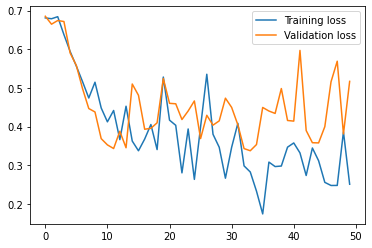

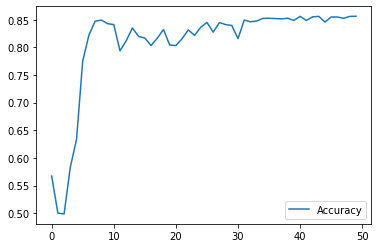

In [9]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show()

Batchnorm

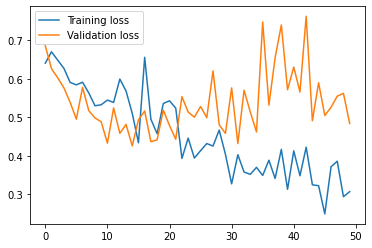

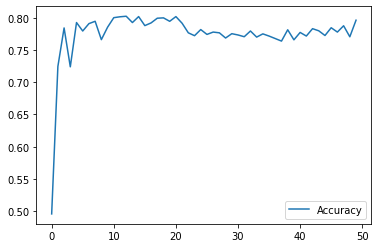

In [52]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show()

2 layer

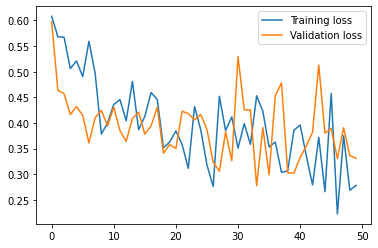

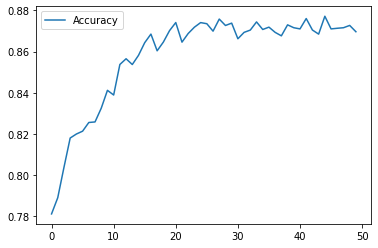

In [46]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show()

5 layer

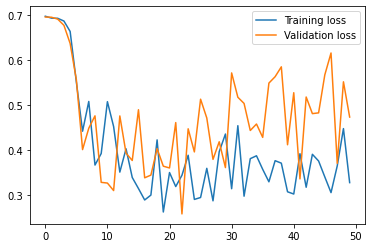

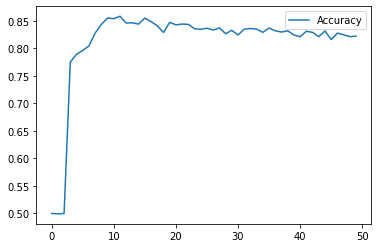

In [38]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show()

4 layers

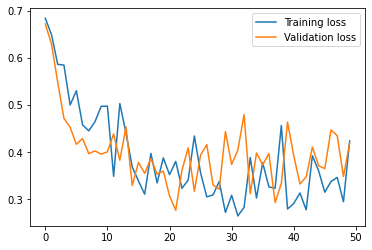

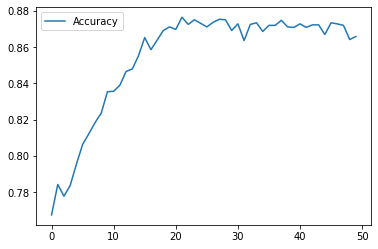

In [30]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show()

verdeel 50/50 pos/neg gevallen, batch size 128, 50epoch

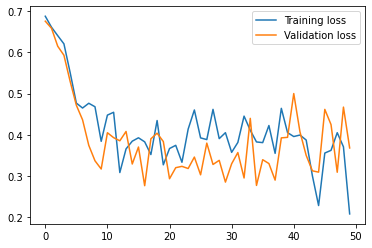

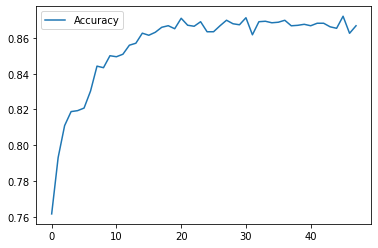

In [11]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show()    

3 layer

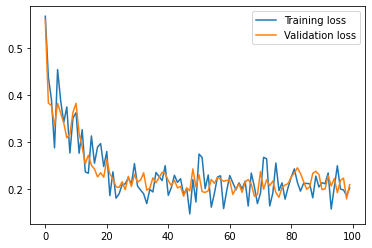

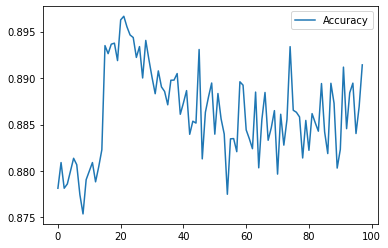

In [132]:

plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy[2:], label='Accuracy')
plt.legend()
plt.show()

Batch size: 1024

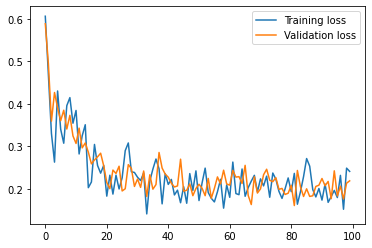

In [117]:
#plt.plot(accuracy, label='Accuracy')
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()

Eerste architectuur bestaat uit 1 binary classifier gevolgd door detectie van yolo op de positieve patches van 512x512

# klasse van netwerk dat gebruikt wordt voor elk model in de architectuur

In [ ]:
class Filter(nn.Module):
    def __init__(self):
        super(Filter, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 8, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(8, 16, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        self.classifier = nn.Sequential(
            nn.Linear(2048, 64),
            nn.ReLU(inplace=True),
            nn.Linear(64, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        x = self.classifier(x)
        return x

model = Filter()
model.cuda()
loss_fun = nn.BCELoss()
optimizer = torch.optim.Adam(model.parameters(),lr = 0.001)

 # TRAINING MODEL 1

Input: 512x512 => 64x64


YOLOv5 detectie over dataset voor GT labels 

In [ ]:
dir_images = "./data/data_512/images_512"
dir_images_rescaled = "./data/data_512/images_512_64"
dir_images_GT = "./data/data_512/images_512_GT"
image_width = 512

train_test_split = 0.7


model = torch.hub.load('ultralytics/yolov5', 'custom', path='./trained_models/yolo_batch16_epoch50.pt')
aantal = len(os.listdir(dir_images))
count = 0
parentdir = "train"
for filename in os.listdir(dir_images):
    short_name = filename.split(".")[0]
    img = skimage.io.imread(f"{dir_images}/{filename}")
    results = model(img)
    df = results.pandas().xyxy[0]
    if not df.empty:
        dir = "positive"
        labels = open(f"./{dir_images_GT}/GT/{short_name}.txt", "a")
        for i in range(len(df.index)):
            values = df.iloc[i]
            xmin, ymin, xmax, ymax = values['xmin'], values['ymin'], values['xmax'], values['ymax']
            labels.write("0\t"+str((xmin+0.5*(xmax-xmin))/image_width)+"\t"+str((ymin+0.5*(ymax-ymin))/image_width)+"\t"+str((xmax-xmin)/image_width)+"\t"+str((ymax-ymin)/image_width)+"\n")
        labels.close()
    else:
        dir = "negative"
    shutil.copy(f"{dir_images_rescaled}/{filename}", f"{dir_images_GT}/{parentdir}/{dir}/{filename}")
    count += 1
    if count % 100 == 0:
        print(f"{count}/{aantal}")
    if count/aantal > train_test_split:
        parentdir = "test"


In [5]:
transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.ImageFolder("./data/data_512/images_512_GT/train", transform=transform)
test_data = datasets.ImageFolder("./data/data_512/images_512_GT/test", transform=transform)

batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,shuffle=True)
print("Size of training set: ", len(train_loader)*batch_size)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=True)
print("Size of test set: ", len(test_loader)*batch_size)

aantal_pos = len(os.listdir("./data/data_512/images_512_GT/train/positive"))
aantal_neg = len(os.listdir("./data/data_512/images_512_GT/train/negative"))
samples = [aantal_pos, aantal_neg]
weights = [1 - (x / sum(samples)) for x in samples]
weights = torch.FloatTensor(weights).cuda()
weights

Size of training set:  8448
Size of test set:  896


tensor([0.8936, 0.1064], device='cuda:0')

In [3]:
def save_model():
    path = "./trained_models/model4.pth"
    torch.save(model.state_dict(), path)

def calculate_weights(labels):
    weights = [0.758 if label == 1.0 else 0.242 for label in labels]
    return torch.FloatTensor(weights)

def test_accuracy():
    model.eval()
    accuracy_list = []
    total = 0.0
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    with torch.no_grad():
        for (images, labels) in test_loader:
            images = Variable(images.to(device))
            labels = Variable(labels.to(device))
            labels = labels.unsqueeze(1).float()
            outputs = model(images)
            test_loss = loss_fun(outputs, labels)
            total += labels.size(0)
            #print(str(outputs))
            outputs = outputs.detach().cpu().numpy()
            for i in range(len(outputs)):
                
                if outputs[i] > 0.5:
                    outputs[i] = 1.0
                else:
                    outputs[i] = 0.0
            #print(outputs)
            accuracy = (outputs == labels.detach().cpu().numpy()).mean()
            accuracy_list.append(accuracy)
    acc = np.mean(accuracy_list)
    return acc, test_loss

def train(epochs):
    best_accuracy = 0.0
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    model.to(device)

    train_losses = []
    test_losses = []
    accuracy_list = []
    for epoch in range(epochs):  # loop over the dataset multiple times
        for i, (images, labels) in enumerate(train_loader, 0):
            images = Variable(images.to(device))
            labels = Variable(labels.to(device))
            optimizer.zero_grad()
            # voorspellingen
            outputs = model(images)
            # bereken loss
            labels = labels.unsqueeze(1).float()
            new_weights = calculate_weights(labels).unsqueeze(1).float().to(device)
            loss_fun = nn.BCELoss(weight=new_weights)
            loss = loss_fun(outputs, labels)
            # loss backpropagation
            loss.backward()
            # weights aanpassen
            optimizer.step()

        accuracy, test_loss = test_accuracy()
        accuracy_list.append(accuracy)
        train_losses.append(loss)
        test_losses.append(test_loss)
        print("Epoch ", epoch+1, ':\tAccuracy: %f %%, training loss: %f, test loss: %f' % (accuracy*100, loss, test_loss))
        
        # sla het beste model op
        if accuracy > best_accuracy:
            save_model()
            best_accuracy = accuracy
    return accuracy_list, train_losses, test_losses

In [125]:
import gc
gc.collect()
torch.cuda.empty_cache()
accuracy, train_losses, test_losses = train(50)
print("finished training...")
test_accuracy()

DEVICE: cuda:0
Epoch  1 :	Accuracy: 82.010582 %, training loss: 0.069962, test loss: 0.532183
Epoch  2 :	Accuracy: 81.068122 %, training loss: 0.115745, test loss: 0.471101
Epoch  3 :	Accuracy: 82.754630 %, training loss: 0.076971, test loss: 0.424126
Epoch  4 :	Accuracy: 80.104993 %, training loss: 0.090676, test loss: 0.472217
Epoch  5 :	Accuracy: 83.213459 %, training loss: 0.056627, test loss: 0.398658
Epoch  6 :	Accuracy: 81.274802 %, training loss: 0.104196, test loss: 0.361914
Epoch  7 :	Accuracy: 84.296462 %, training loss: 0.054511, test loss: 0.483110
Epoch  8 :	Accuracy: 84.552745 %, training loss: 0.089500, test loss: 0.393867
Epoch  9 :	Accuracy: 84.358466 %, training loss: 0.079143, test loss: 0.429711
Epoch  10 :	Accuracy: 82.713294 %, training loss: 0.065214, test loss: 0.494788
Epoch  11 :	Accuracy: 84.122851 %, training loss: 0.091064, test loss: 0.497639
Epoch  12 :	Accuracy: 84.093915 %, training loss: 0.050725, test loss: 0.428355
Epoch  13 :	Accuracy: 84.623016 %,

(0.7945601851851851, tensor(0.5871, device='cuda:0'))

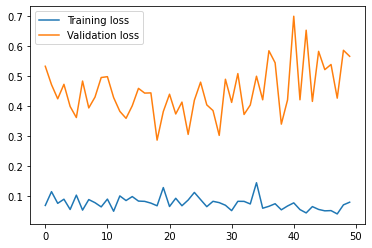

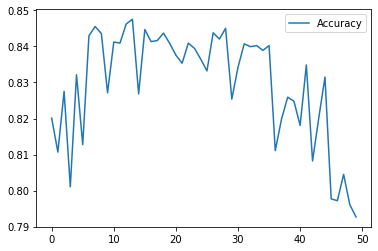

In [126]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show() 

## Testing model 1

In [ ]:
model.load_state_dict(torch.load("./trained_models/model1.pth"))
model.eval()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
transform = transforms.Compose([transforms.ToTensor()])
test_data = datasets.ImageFolder("./data/data_512/images_512_GT/test", transform=transform)

batch_size = 128
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=False)

images_total = test_loader.dataset.samples
predicted_total = []
for i, (images, labels) in enumerate(test_loader, 0):
    images = images.to(device)
    output = model(images)
    output = output.to(device)
    index = output.data.cpu().numpy()
    predictions_batch = index.flatten().tolist()
    predicted_total.extend(predictions_batch)

filtered_data = []
for i in range(len(images_total)):
    if predicted_total[i] > 0.5:
        filtered_data.append(images_total[i])
    print("bestandsnaam: {}, voorspeld: {}\n".format(images_total[i], predicted_total[i]))

In [ ]:

y_true = [i[1] for i in images_total]
y_pred = predicted_total
y_pred

0.8945549508976043


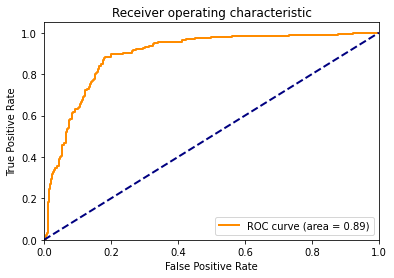

In [6]:
fpr, tpr, threshhold = metrics.roc_curve(y_true, y_pred)
roc_auc = metrics.auc(fpr, tpr)
print(roc_auc)

plt.figure()
lw = 2
plt.plot(
    fpr,
    tpr,
    color="darkorange",
    lw=lw,
    label="ROC curve (area = %0.2f)" % roc_auc,
)
plt.plot([0, 1], [0, 1], color="navy", lw=lw, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver operating characteristic")
plt.legend(loc="lower right")
plt.show()

## Filtering for next model

Eerst wordt de gefilterde data verknipt in vier en gedownscaled naar 64x64. Daarna gebeurt volgende code

In [38]:
dir_to_filter = "./data/data_512/images_1-4_64"
dir_filtered = "./data/data_512/images_1-4_64_filtered"
labels = "./data/data_512/labels_1-4"
labels_filtered = "./data/data_512/labels_1-4_filtered"

dir_list = os.listdir(dir_to_filter)
label_list = os.listdir(labels)

for row in filtered_data:
    filename = row[0].split("\\")[2].split(".")[0]
    truth = list(filter(lambda x: filename+"_" in x, dir_list))
    for i in truth:
        labelname = i.split(".")[0] + ".txt"
        if labelname in label_list:
            shutil.copy(f"{labels}/{labelname}", f"{labels_filtered}/{labelname}")
            shutil.copy(f"{dir_to_filter}/{i}", f"{dir_filtered}/positive/{i}")
        else:
            shutil.copy(f"{dir_to_filter}/{i}", f"{dir_filtered}/negative/{i}")
    


 # TRAINING MODEL 2

In [4]:
transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.ImageFolder("./data/data_512/images_1-4_64_filtered/train", transform=transform)
test_data = datasets.ImageFolder("./data/data_512/images_1-4_64_filtered/test", transform=transform)

batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,shuffle=True)
print("Size of training set: ", len(train_loader)*batch_size)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=True)
print("Size of test set: ", len(test_loader)*batch_size)

aantal_pos = len(os.listdir("./data/data_512/images_1-4_64_filtered/train/positive"))
aantal_neg = len(os.listdir("./data/data_512/images_1-4_64_filtered/train/negative"))
samples = [aantal_pos, aantal_neg]
weights = [1 - (x / sum(samples)) for x in samples]
weights = torch.FloatTensor(weights).cuda()
weights

Size of training set:  7936
Size of test set:  3456


tensor([0.8721, 0.1279], device='cuda:0')

In [5]:
import gc
gc.collect()
torch.cuda.empty_cache()
accuracy, train_losses, test_losses = train(50)
print("finished training...")
test_accuracy()

DEVICE: cuda:0
Epoch  1 :	Accuracy: 19.799731 %, training loss: 0.152863, test loss: 0.699590
Epoch  2 :	Accuracy: 50.788365 %, training loss: 0.156834, test loss: 0.649940
Epoch  3 :	Accuracy: 44.801628 %, training loss: 0.144083, test loss: 0.566226
Epoch  4 :	Accuracy: 41.448467 %, training loss: 0.121927, test loss: 0.664956
Epoch  5 :	Accuracy: 36.593048 %, training loss: 0.158469, test loss: 0.704593
Epoch  6 :	Accuracy: 65.400159 %, training loss: 0.115237, test loss: 0.500419
Epoch  7 :	Accuracy: 57.252296 %, training loss: 0.123696, test loss: 0.566989
Epoch  8 :	Accuracy: 45.342858 %, training loss: 0.140639, test loss: 0.710551
Epoch  9 :	Accuracy: 37.736225 %, training loss: 0.110800, test loss: 0.714498
Epoch  10 :	Accuracy: 46.254554 %, training loss: 0.165512, test loss: 0.720620
Epoch  11 :	Accuracy: 62.912208 %, training loss: 0.169008, test loss: 0.640743
Epoch  12 :	Accuracy: 62.009051 %, training loss: 0.117293, test loss: 0.676255
Epoch  13 :	Accuracy: 43.236756 %,

(0.7889534001214329, tensor(0.7619, device='cuda:0'))

In [ ]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show() 

## Filtering for model 3

In [ ]:
model.load_state_dict(torch.load("./trained_models/model2.pth"))
model.eval()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
transform = transforms.Compose([transforms.ToTensor()])
test_data = datasets.ImageFolder("./data/data_512/images_1-4_64_filtered/train", transform=transform)

batch_size = 128
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=False)

images_total = test_loader.dataset.samples
predicted_total = []
for i, (images, labels) in enumerate(test_loader, 0):
    images = images.to(device)
    output = model(images)
    output = output.to(device)
    index = output.data.cpu().numpy()
    predictions_batch = index.flatten().tolist()
    predicted_total.extend(predictions_batch)

filtered_data = []
for i in range(len(images_total)):
    if predicted_total[i] > 0.5:
        filtered_data.append(images_total[i])
    print("bestandsnaam: {}, voorspeld: {}\n".format(images_total[i], predicted_total[i]))

dir_to_filter = "./data/data_512/images_1-16_64"
dir_filtered = "./data/data_512/images_1-16_64_filtered"
labels = "./data/data_512/labels_1-16"
labels_filtered = "./data/data_512/labels_1-16_filtered"

dir_list = os.listdir(dir_to_filter)
label_list = os.listdir(labels)

for row in filtered_data:
    filename = row[0].split("\\")[2].split(".")[0]
    truth = list(filter(lambda x: filename+"_" in x, dir_list))
    for i in truth:
        labelname = i.split(".")[0] + ".txt"
        if labelname in label_list:
            shutil.copy(f"{labels}/{labelname}", f"{labels_filtered}/{labelname}")
            shutil.copy(f"{dir_to_filter}/{i}", f"{dir_filtered}/positive/{i}")
        else:
            shutil.copy(f"{dir_to_filter}/{i}", f"{dir_filtered}/negative/{i}")

 # TRAINING MODEL 3

In [13]:
transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.ImageFolder("./data/data_512/images_1-16_64_filtered/train", transform=transform)
test_data = datasets.ImageFolder("./data/data_512/images_1-16_64_filtered/test", transform=transform)

batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,shuffle=True)
print("Size of training set: ", len(train_loader)*batch_size)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=True)
print("Size of test set: ", len(test_loader)*batch_size)

aantal_pos = len(os.listdir("./data/data_512/images_1-16_64_filtered/train/positive"))
aantal_neg = len(os.listdir("./data/data_512/images_1-16_64_filtered/train/negative"))
samples = [aantal_pos, aantal_neg]
weights = [1 - (x / sum(samples)) for x in samples]
weights = torch.FloatTensor(weights).cuda()
weights

Size of training set:  3840
Size of test set:  1664


tensor([0.7900, 0.2100], device='cuda:0')

In [17]:
import gc
gc.collect()
torch.cuda.empty_cache()
accuracy, train_losses, test_losses = train(50)
print("finished training...")
test_accuracy()

DEVICE: cuda:0
Epoch  1 :	Accuracy: 30.090049 %, training loss: 0.216119, test loss: 0.695831
Epoch  2 :	Accuracy: 77.615614 %, training loss: 0.181461, test loss: 0.655314
Epoch  3 :	Accuracy: 21.360844 %, training loss: 0.257157, test loss: 0.820230
Epoch  4 :	Accuracy: 31.945398 %, training loss: 0.255381, test loss: 0.718833
Epoch  5 :	Accuracy: 75.142132 %, training loss: 0.240602, test loss: 0.639829
Epoch  6 :	Accuracy: 76.601610 %, training loss: 0.195690, test loss: 0.443490
Epoch  7 :	Accuracy: 82.605502 %, training loss: 0.175835, test loss: 0.504138
Epoch  8 :	Accuracy: 84.053533 %, training loss: 0.166111, test loss: 0.501338
Epoch  9 :	Accuracy: 88.205891 %, training loss: 0.057653, test loss: 0.370933
Epoch  10 :	Accuracy: 85.905067 %, training loss: 0.194906, test loss: 0.599865
Epoch  11 :	Accuracy: 90.380800 %, training loss: 0.121672, test loss: 0.232456
Epoch  12 :	Accuracy: 86.947688 %, training loss: 0.143406, test loss: 0.311363
Epoch  13 :	Accuracy: 89.291438 %,

(0.9236397283272283, tensor(0.1895, device='cuda:0'))

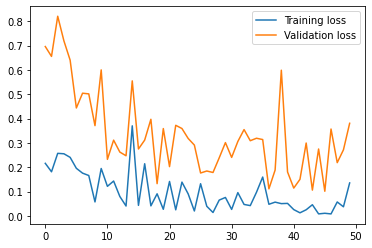

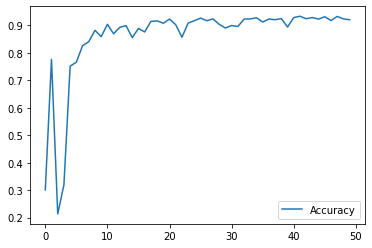

In [18]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show() 

## Filtering for model 4

In [ ]:
model.load_state_dict(torch.load("./trained_models/model3.pth"))
model.eval()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
transform = transforms.Compose([transforms.ToTensor()])
test_data = datasets.ImageFolder("./data/data_512/images_1-16_64_filtered/train", transform=transform)

batch_size = 128
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=False)

images_total = test_loader.dataset.samples
predicted_total = []
for i, (images, labels) in enumerate(test_loader, 0):
    images = images.to(device)
    output = model(images)
    output = output.to(device)
    index = output.data.cpu().numpy()
    predictions_batch = index.flatten().tolist()
    predicted_total.extend(predictions_batch)

filtered_data = []
for i in range(len(images_total)):
    if predicted_total[i] > 0.5:
        filtered_data.append(images_total[i])
    print("bestandsnaam: {}, voorspeld: {}\n".format(images_total[i], predicted_total[i]))

dir_to_filter = "./data/data_512/images_1-64_64"
dir_filtered = "./data/data_512/images_1-64_64_filtered"
labels = "./data/data_512/labels_1-64"
labels_filtered = "./data/data_512/labels_1-64_filtered"

dir_list = os.listdir(dir_to_filter)
label_list = os.listdir(labels)

for row in filtered_data:
    filename = row[0].split("\\")[2].split(".")[0]
    truth = list(filter(lambda x: filename+"_" in x, dir_list))
    for i in truth:
        labelname = i.split(".")[0] + ".txt"
        if labelname in label_list:
            shutil.copy(f"{labels}/{labelname}", f"{labels_filtered}/{labelname}")
            shutil.copy(f"{dir_to_filter}/{i}", f"{dir_filtered}/positive/{i}")
        else:
            shutil.copy(f"{dir_to_filter}/{i}", f"{dir_filtered}/negative/{i}")

 # TRAINING MODEL 4

In [33]:
transform = transforms.Compose([transforms.ToTensor()])
train_data = datasets.ImageFolder("./data/data_512/images_1-64_64_filtered/train", transform=transform)
test_data = datasets.ImageFolder("./data/data_512/images_1-64_64_filtered/test", transform=transform)

batch_size = 128
train_loader = torch.utils.data.DataLoader(train_data, batch_size=batch_size,shuffle=True)
print("Size of training set: ", len(train_loader)*batch_size)
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=True)
print("Size of test set: ", len(test_loader)*batch_size)

aantal_pos = len(os.listdir("./data/data_512/images_1-64_64_filtered/train/positive"))
aantal_neg = len(os.listdir("./data/data_512/images_1-64_64_filtered/train/negative"))
samples = [aantal_pos, aantal_neg]
weights = [1 - (x / sum(samples)) for x in samples]
weights = torch.FloatTensor(weights).cuda()
weights

Size of training set:  3200
Size of test set:  1408


tensor([0.7581, 0.2419], device='cuda:0')

In [34]:
import gc
gc.collect()
torch.cuda.empty_cache()
accuracy, train_losses, test_losses = train(30)
print("finished training...")
test_accuracy()

DEVICE: cuda:0
Epoch  1 :	Accuracy: 57.870610 %, training loss: 0.274484, test loss: 0.692663
Epoch  2 :	Accuracy: 71.875000 %, training loss: 0.199822, test loss: 0.683043
Epoch  3 :	Accuracy: 71.255165 %, training loss: 0.209900, test loss: 0.687788
Epoch  4 :	Accuracy: 88.513688 %, training loss: 0.116738, test loss: 2.538574
Epoch  5 :	Accuracy: 89.036674 %, training loss: 0.137574, test loss: 0.426556
Epoch  6 :	Accuracy: 90.437758 %, training loss: 0.037037, test loss: 0.454213
Epoch  7 :	Accuracy: 91.270661 %, training loss: 0.078121, test loss: 0.273884
Epoch  8 :	Accuracy: 92.271436 %, training loss: 0.052634, test loss: 0.151963
Epoch  9 :	Accuracy: 90.954287 %, training loss: 0.094542, test loss: 0.570584
Epoch  10 :	Accuracy: 92.549070 %, training loss: 0.165667, test loss: 0.088573
Epoch  11 :	Accuracy: 92.904184 %, training loss: 0.023800, test loss: 0.099151
Epoch  12 :	Accuracy: 92.348915 %, training loss: 0.043992, test loss: 0.210119
Epoch  13 :	Accuracy: 90.657283 %,

(0.9108341942148761, tensor(0.2884, device='cuda:0'))

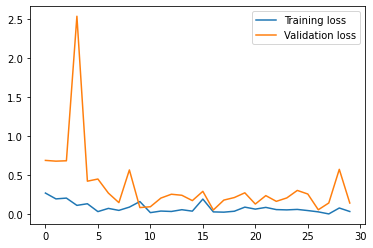

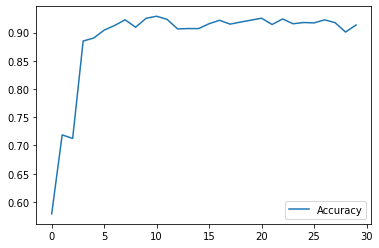

In [35]:
plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.legend()
plt.show()
plt.plot(accuracy, label='Accuracy')
plt.legend()
plt.show() 

In [ ]:
model.load_state_dict(torch.load("./trained_models/model4.pth"))
model.eval()
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
transform = transforms.Compose([transforms.ToTensor()])
test_data = datasets.ImageFolder("./data/data_512/images_1-64_64_filtered/test", transform=transform)

batch_size = 128
test_loader = torch.utils.data.DataLoader(test_data, batch_size=batch_size,shuffle=False)

images_total = test_loader.dataset.samples
predicted_total = []
for i, (images, labels) in enumerate(test_loader, 0):
    images = images.to(device)
    output = model(images)
    output = output.to(device)
    index = output.data.cpu().numpy()
    predictions_batch = index.flatten().tolist()
    predicted_total.extend(predictions_batch)

filtered_data = []
for i in range(len(images_total)):
    if predicted_total[i] > 0.5:
        filtered_data.append(images_total[i])
    print("bestandsnaam: {}, voorspeld: {}\n".format(images_total[i], predicted_total[i]))